# Can the Baby GOAT Surpass the GOAT?
## 03 — Era-Adjusted Quarterback Performance

**Research question.** How did Tom Brady and Patrick Mahomes perform relative to the NFL environment of their respective seasons during their **first 131 regular-season starts**?

**Unit of comparison:** QB-attributed Expected Points Added (QB EPA) on eligible dropbacks (passes, sacks, and scrambles). The validated upstream pipeline restores historically tagged scrambles that were not flagged as dropbacks in the original PBP data.

This notebook is an **observational, descriptive comparison**, not an estimate of individual talent or causal QB impact. It does not assume the two quarterbacks played in identical team situations.

### Definitions

For quarterback $q$ in game $g$ of season $s$:

$$\text{Absolute QB EPA/DB}_{g}=\frac{\sum_{i\in g}\mathrm{QB\ EPA}_i}{N_g}$$

$$\text{Season-relative QB EPA/DB}_{g}=\text{Absolute QB EPA/DB}_g-\mu_s$$

where $N_g$ is the number of usable eligible dropbacks and $\mu_s$ is the NFL **dropback-weighted** mean QB EPA for season $s$.

We aggregate the first 131 starts by **total dropbacks**, not by taking an unweighted mean of game-level rates:

$$\text{Relative EPA/DB}_{131}=\frac{\sum_g(\mathrm{QB\ EPA}_g-N_g\mu_{s(g)})}{\sum_g N_g}$$

**Also included:** a season-standardized effect size, $(\mathrm{QB\ EPA/DB}-\mu_s)/\sigma_s$, where $\sigma_s$ is the **league play-level** standard deviation of QB EPA in that season. It is *not* a QB-rank z-score, a sampling z-statistic, or a QB percentile.

**Not yet estimated:** qualified-QB season percentiles (requires a validated league-wide, qualified-QB cohort) and three-year relative EPA/DB (requires an explicitly defined smoothing window and sufficient adjacent seasons). These will be separate methodological extensions.

## 1. Environment and validated sources

Run from the repository root with `jupyter lab`, or open the notebook from `notebooks/`. All inputs are **read-only** and generated by the validated processing scripts. Charts will be saved under `reports/figures/`.

Required inputs:

- `data/processed/nfl_season_dropback_baselines.parquet`
- `data/processed/qb_game_era_adjusted.parquet`
- `data/processed/qb_study_season_era_summary.parquet`
- `data/processed/qb_first_131_era_summary.parquet`

To rebuild inputs: run `scripts/build_nfl_epa_baselines.py` and then `scripts/build_qb_era_adjusted_stats.py`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import Markdown, display

# Team color palette from the established descriptive-analysis visuals.
COLORS = {
    "Tom Brady": "#002244",       # New England Patriots
    "Patrick Mahomes": "#E31837", # Kansas City Chiefs
}
ORDER = ["Tom Brady", "Patrick Mahomes"]
INK = "#17202A"
SUBTLE = "#64748B"
GRID = "#E2E8F0"

# Detect the repository root whether Jupyter starts in root/ or notebooks/.
search_roots = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (p for p in search_roots if (p / "data/processed/qb_game_era_adjusted.parquet").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Cannot locate data/processed/qb_game_era_adjusted.parquet. "
        "Open Jupyter from the project root and run the data pipeline first."
    )

PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

paths = {
    "games": PROCESSED / "qb_game_era_adjusted.parquet",
    "seasons": PROCESSED / "qb_study_season_era_summary.parquet",
    "career": PROCESSED / "qb_first_131_era_summary.parquet",
    "league": PROCESSED / "nfl_season_dropback_baselines.parquet",
}
missing_files = [str(p) for p in paths.values() if not p.is_file()]
if missing_files:
    raise FileNotFoundError("Missing validated inputs:\n" + "\n".join(missing_files))

games = pl.read_parquet(paths["games"])
seasons = pl.read_parquet(paths["seasons"])
career = pl.read_parquet(paths["career"])
league = pl.read_parquet(paths["league"])

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 11,
    "axes.edgecolor": "#CBD5E1",
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": SUBTLE,
    "ytick.color": SUBTLE,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})

print(f"Project: {ROOT}")
print(f"Games: {games.height} | Study-season rows: {seasons.height} | "
      f"Career rows: {career.height} | League seasons: {league.height}")

Project: /home/lucas/2110/mahomes-brady
Games: 262 | Study-season rows: 20 | Career rows: 2 | League seasons: 20


## 2. Quality gates — fail before interpretation

These checks verify the research sample, unique keys, denominators, baseline coverage, and reconciliation between game and career totals. **Do not remove a failing assertion simply to display the figures.** Check the upstream processing if anything changes.

In [2]:
REQUIRED_GAMES = {
    "player_id", "player_name", "game_id", "start_no", "season",
    "usable_dropbacks", "qb_epa_sum", "qb_epa_per_dropback",
    "relative_qb_epa_total", "relative_qb_epa_per_dropback",
    "league_qb_epa_per_dropback", "qb_epa_success_rate",
    "relative_qb_epa_success_rate_pp",
}
REQUIRED_SEASONS = {
    "player_id", "player_name", "season", "starts", "usable_dropbacks",
    "qb_epa_per_dropback", "relative_qb_epa_per_dropback",
}
REQUIRED_CAREER = {
    "player_id", "player_name", "starts", "usable_dropbacks",
    "qb_epa_sum", "relative_qb_epa_total", "qb_epa_per_dropback",
    "relative_qb_epa_per_dropback", "expected_league_epa_per_dropback",
    "relative_qb_epa_success_rate_pp",
}
REQUIRED_LEAGUE = {
    "season", "baseline_scope", "usable_dropbacks",
    "league_qb_epa_per_dropback", "league_qb_epa_std",
}
for name, data, required in [
    ("games", games, REQUIRED_GAMES),
    ("study seasons", seasons, REQUIRED_SEASONS),
    ("career", career, REQUIRED_CAREER),
    ("league", league, REQUIRED_LEAGUE),
]:
    missing_cols = required - set(data.columns)
    assert not missing_cols, f"{name}: missing columns {sorted(missing_cols)}"

assert games.height == 262, "Expected exactly 262 starts"
assert career.height == 2, "Expected two quarterbacks"
assert league.height == 20, "Expected 20 NFL season baselines"
assert games.select(pl.struct("player_id", "game_id").n_unique()).item() == 262
assert league["season"].n_unique() == 20
assert sorted(games["season"].unique().to_list()) == sorted(league["season"].to_list())
assert set(games["player_name"].unique().to_list()) == set(ORDER)
assert not games.filter(pl.col("usable_dropbacks") <= 0).height
assert not league.filter(pl.col("league_qb_epa_std") <= 0).height

for player in ORDER:
    segment = games.filter(pl.col("player_name") == player).sort("start_no")
    assert segment.height == 131, f"{player}: expected 131 starts"
    assert segment["start_no"].to_list() == list(range(1, 132))
    row = career.filter(pl.col("player_name") == player).row(0, named=True)
    assert row["starts"] == 131
    assert int(segment["usable_dropbacks"].sum()) == int(row["usable_dropbacks"])
    assert np.isclose(float(segment["qb_epa_sum"].sum()), float(row["qb_epa_sum"]), atol=1e-6)
    assert np.isclose(float(segment["relative_qb_epa_total"].sum()),
                      float(row["relative_qb_epa_total"]), atol=1e-6)
    observed = float(row["relative_qb_epa_total"]) / float(row["usable_dropbacks"])
    assert np.isclose(observed, float(row["relative_qb_epa_per_dropback"]), atol=1e-10)

# All 2026 NFL context is explicitly partial, ending with the study date.
assert league.filter(pl.col("season") == 2026)["baseline_scope"].item() == "through_study_date"
assert league.filter(pl.col("season") != 2026).filter(
    pl.col("baseline_scope") != "full_regular_season"
).height == 0

print("PASS: 262 unique starts, 131 per QB, 20 matching baselines, valid denominators, reconciled career totals.")

PASS: 262 unique starts, 131 per QB, 20 matching baselines, valid denominators, reconciled career totals.


## 3. Figure 1 — What was the league environment?

This figure shows the **dropback-weighted NFL average** for each study season, not the performance of either quarterback. The two panels deliberately separate eras instead of drawing an artificial line across the missing 2011–2016 period.

**Interpretation prompts:** Which seasons had the highest/lowest league averages? Did the average rise monotonically over time? How should we treat the provisional 2026 baseline?

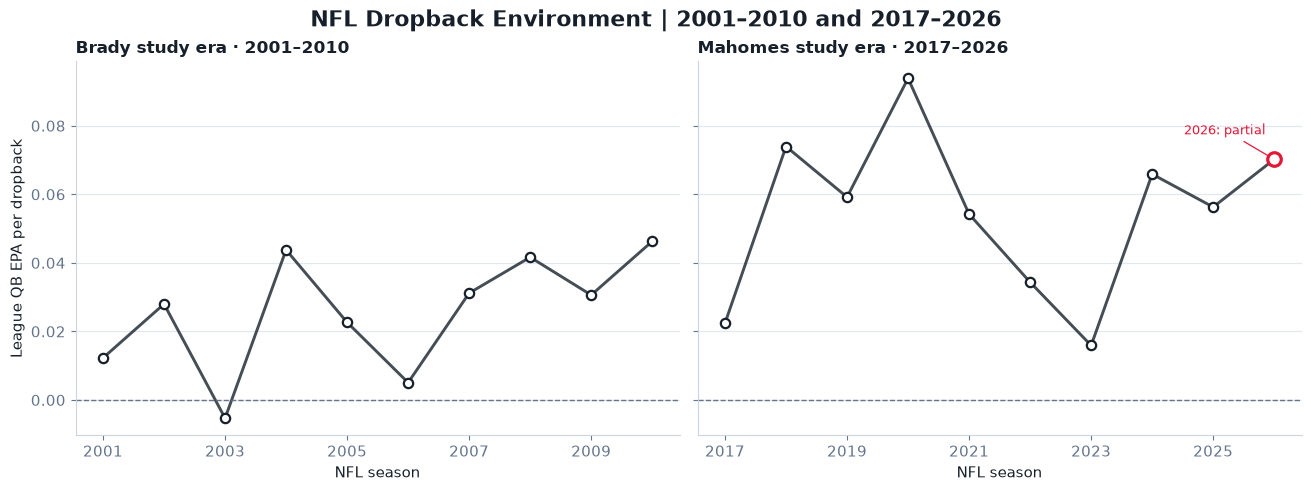

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True, layout="constrained")
for ax, years, subtitle in zip(
    axs,
    [range(2001, 2011), range(2017, 2027)],
    ["Brady study era · 2001–2010", "Mahomes study era · 2017–2026"],
):
    table = league.filter(pl.col("season").is_in(list(years))).sort("season")
    x = np.asarray(table["season"].to_list(), dtype=int)
    y = np.asarray(table["league_qb_epa_per_dropback"].to_list(), dtype=float)
    ax.plot(x, y, color=INK, linewidth=2.1, alpha=0.8, zorder=2)
    ax.scatter(x[:-1], y[:-1], s=45, facecolor="white", edgecolor=INK,
               linewidth=1.6, zorder=3)
    # Plot the final year explicitly; 2026 uses a hollow marker and a note.
    if x[-1] == 2026:
        ax.scatter([x[-1]], [y[-1]], s=95, facecolor="white",
                   edgecolor=COLORS["Patrick Mahomes"], linewidth=2.3, zorder=4)
        ax.annotate("2026: partial", xy=(x[-1], y[-1]), xytext=(-65, 18),
                    textcoords="offset points", fontsize=9, color=COLORS["Patrick Mahomes"],
                    arrowprops=dict(arrowstyle="-", color=COLORS["Patrick Mahomes"], lw=0.9))
    else:
        ax.scatter([x[-1]], [y[-1]], s=45, facecolor="white", edgecolor=INK,
                   linewidth=1.6, zorder=3)
    ax.axhline(0, color=SUBTLE, linewidth=1, linestyle="--")
    ax.set_xticks(x[::2])
    ax.set_title(subtitle, loc="left", fontsize=12, weight="semibold")
    ax.grid(axis="y", color=GRID, linewidth=0.9)
    ax.spines[["right", "top"]].set_visible(False)
    ax.set_xlabel("NFL season")
axs[0].set_ylabel("League QB EPA per dropback")
fig.suptitle("NFL Dropback Environment | 2001–2010 and 2017–2026",
             fontsize=16, weight="bold")
fig.savefig(FIGURES / "04_nfl_era_baselines.png", dpi=220, bbox_inches="tight")
plt.show()

## 4. Figure 2 — The first 131 starts: absolute vs season-relative EPA

Every headline number is **dropback-weighted**. The expected NFL value for each QB is itself weighted according to *that QB's distribution of dropbacks across seasons*. It is generally not identical to the unweighted average of league season means.

The colored mark is observed QB EPA/DB, the gray mark is the matching league expectation, and the difference between them is **season-relative EPA/DB**. No inference about individual talent follows from these descriptive differences alone.

| Quarterback | Dropbacks | Absolute QB EPA/DB | Era-matched NFL EPA/DB | Relative QB EPA/DB | Relative success rate (pp) |
|:--|--:|--:|--:|--:|--:|
| Tom Brady | 4,607 | +0.1761 | +0.0220 | +0.1542 | +4.23 |
| Patrick Mahomes | 5,381 | +0.2486 | +0.0563 | +0.1923 | +5.86 |

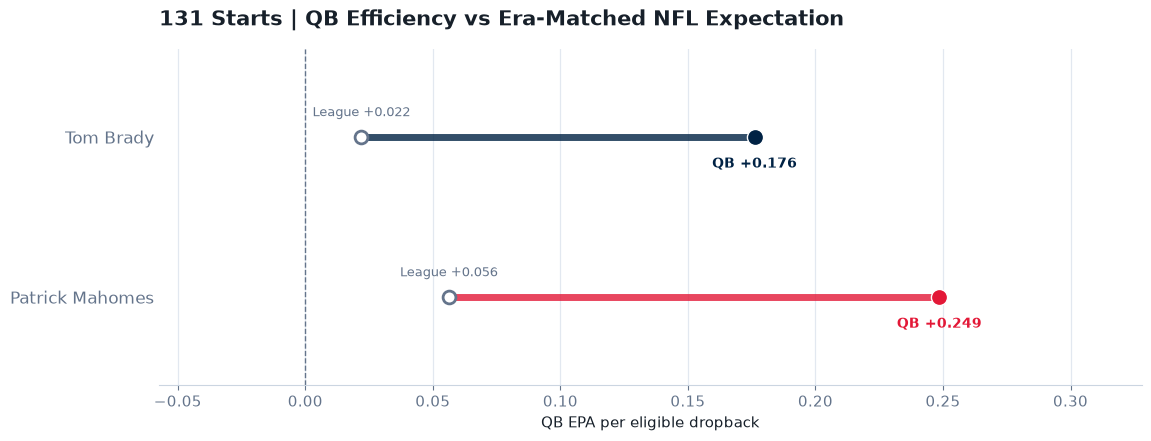

Higher observed era-relative QB EPA/DB: Patrick Mahomes (difference: +0.0381 EPA/DB).
This is a descriptive difference, not a QB-only causal effect or significance test.


In [5]:
rows = {r["player_name"]: r for r in career.to_dicts()}
lines = [
    "| Quarterback | Dropbacks | Absolute QB EPA/DB | Era-matched NFL EPA/DB | Relative QB EPA/DB | Relative success rate (pp) |",
    "|:--|--:|--:|--:|--:|--:|",
]
for player in ORDER:
    r = rows[player]
    lines.append(
        f"| {player} | {int(r['usable_dropbacks']):,} | "
        f"{r['qb_epa_per_dropback']:+.4f} | "
        f"{r['expected_league_epa_per_dropback']:+.4f} | "
        f"{r['relative_qb_epa_per_dropback']:+.4f} | "
        f"{r['relative_qb_epa_success_rate_pp']:+.2f} |"
    )
display(Markdown("\n".join(lines)))

values = [
    float(rows[p][k])
    for p in ORDER
    for k in ["qb_epa_per_dropback", "expected_league_epa_per_dropback"]
]
lo, hi = min(values), max(values)
span = max(hi - lo, 0.08)
fig, ax = plt.subplots(figsize=(11.4, 4.3), layout="constrained")
for i, player in enumerate(ORDER):
    r = rows[player]
    qb = float(r["qb_epa_per_dropback"])
    baseline = float(r["expected_league_epa_per_dropback"])
    color = COLORS[player]
    y = len(ORDER) - i
    ax.plot([baseline, qb], [y, y], color=color, alpha=0.80, linewidth=5,
            solid_capstyle="round", zorder=1)
    ax.scatter([baseline], [y], s=85, facecolor="white", edgecolor=SUBTLE,
               linewidth=2, zorder=3)
    ax.scatter([qb], [y], s=135, facecolor=color, edgecolor="white",
               linewidth=1, zorder=4)
    ax.annotate(f"League {baseline:+.3f}", (baseline, y), xytext=(0, 15),
                textcoords="offset points", ha="center", fontsize=9, color=SUBTLE)
    ax.annotate(f"QB {qb:+.3f}", (qb, y), xytext=(0, -22),
                textcoords="offset points", ha="center", fontsize=10,
                color=color, weight="bold")
ax.axvline(0, color=SUBTLE, linestyle="--", linewidth=1)
ax.set_xlim(lo - 0.35 * span, hi + 0.35 * span)
ax.set_yticks([2, 1], ORDER)
ax.set_ylim(0.45, 2.55)
ax.grid(axis="x", color=GRID, linewidth=0.9)
ax.set_axisbelow(True)
ax.spines[["right", "top", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=12)
ax.set_xlabel("QB EPA per eligible dropback")
ax.set_title("131 Starts | QB Efficiency vs Era-Matched NFL Expectation",
             fontsize=15, weight="bold", loc="left", pad=17)
fig.savefig(FIGURES / "05_qb_vs_era_baseline_131.png", dpi=220, bbox_inches="tight")
plt.show()

leader = max(ORDER, key=lambda p: float(rows[p]["relative_qb_epa_per_dropback"]))
follower = next(p for p in ORDER if p != leader)
delta = float(rows[leader]["relative_qb_epa_per_dropback"]) - float(rows[follower]["relative_qb_epa_per_dropback"])
print(f"Higher observed era-relative QB EPA/DB: {leader} (difference: {delta:+.4f} EPA/DB).")
print("This is a descriptive difference, not a QB-only causal effect or significance test.")

## 5. Figure 3 — Which study seasons contributed to the result?

Season bars represent **only the starts selected within the first-131-start sample**, not the player's entire season. Therefore, a one-start season can be extreme without carrying much weight in the 131-start aggregate.

Key small-sample cases: Brady **2008 (1 start)**, Brady **2010 (4 starts)**, Mahomes **2017 (1 start)**, and Mahomes **2026 (5 starts, partial NFL baseline)**.

**Interpretation prompts:** Which stretches were above/below their contemporary league mean? Do unusually high/low bars have many dropbacks? How different is the 131-start result from any single season?

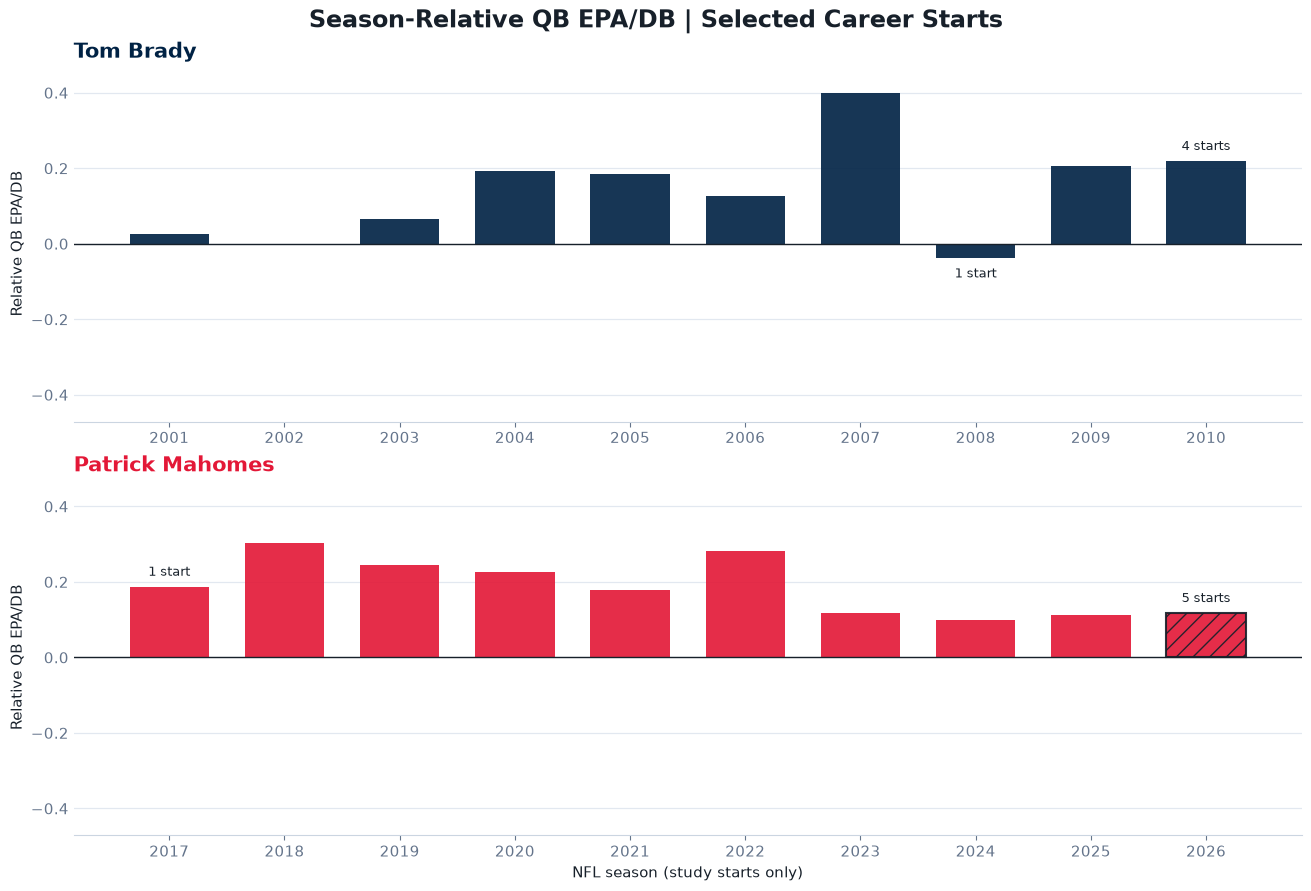

In [6]:
season_rows = seasons.to_dicts()
max_abs = max(abs(float(r["relative_qb_epa_per_dropback"])) for r in season_rows)
scale = max(max_abs * 1.18, 0.06)
fig, axs = plt.subplots(2, 1, figsize=(13, 8.8), sharey=True, layout="constrained")
for ax, player in zip(axs, ORDER):
    data = sorted((r for r in season_rows if r["player_name"] == player),
                  key=lambda r: int(r["season"]))
    xs = np.arange(len(data))
    ys = np.array([float(r["relative_qb_epa_per_dropback"]) for r in data])
    bars = ax.bar(xs, ys, width=0.69, color=COLORS[player], alpha=0.91)
    for bar, row, val in zip(bars, data, ys):
        if int(row["starts"]) <= 5:
            ax.annotate(f"{row['starts']} start{'s' if row['starts'] != 1 else ''}",
                        (bar.get_x() + bar.get_width()/2, val),
                        xytext=(0, 6 if val >= 0 else -7), textcoords="offset points",
                        ha="center", va="bottom" if val >= 0 else "top",
                        fontsize=9, color=INK)
        if int(row["season"]) == 2026:
            bar.set_edgecolor(INK)
            bar.set_linewidth(1.5)
            bar.set_hatch("//")
    ax.set_xticks(xs, [str(r["season"]) for r in data])
    ax.axhline(0, color=INK, linewidth=1)
    ax.set_ylim(-scale, scale)
    ax.set_ylabel("Relative QB EPA/DB")
    ax.set_title(player, loc="left", weight="bold", color=COLORS[player])
    ax.grid(axis="y", color=GRID, linewidth=0.9)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
axs[1].set_xlabel("NFL season (study starts only)")
fig.suptitle("Season-Relative QB EPA/DB | Selected Career Starts",
             fontsize=17, weight="bold")
fig.savefig(FIGURES / "06_season_relative_qb_epa.png", dpi=220, bbox_inches="tight")
plt.show()

## 6. Figure 4 — How did the era-relative advantage evolve over 131 starts?

The cumulative series uses **all dropbacks up to a given career start**:

$$\mathrm{Cumulative\ relative\ EPA/DB}(k)=\frac{\sum_{g=1}^{k}\mathrm{Relative\ EPA}_g}{\sum_{g=1}^{k} N_g}$$

A rolling **16-start** series shows local variation using the most recent 16 starts, also weighted by the number of dropbacks. This is a *game-window*, not a three-year season-relative benchmark. Early cumulative observations are unstable because they are based on small samples.

**Interpretation prompts:** Does the advantage persist throughout the sample? Are there different phases? Do high peaks or troughs depend on individual games or sustained runs?

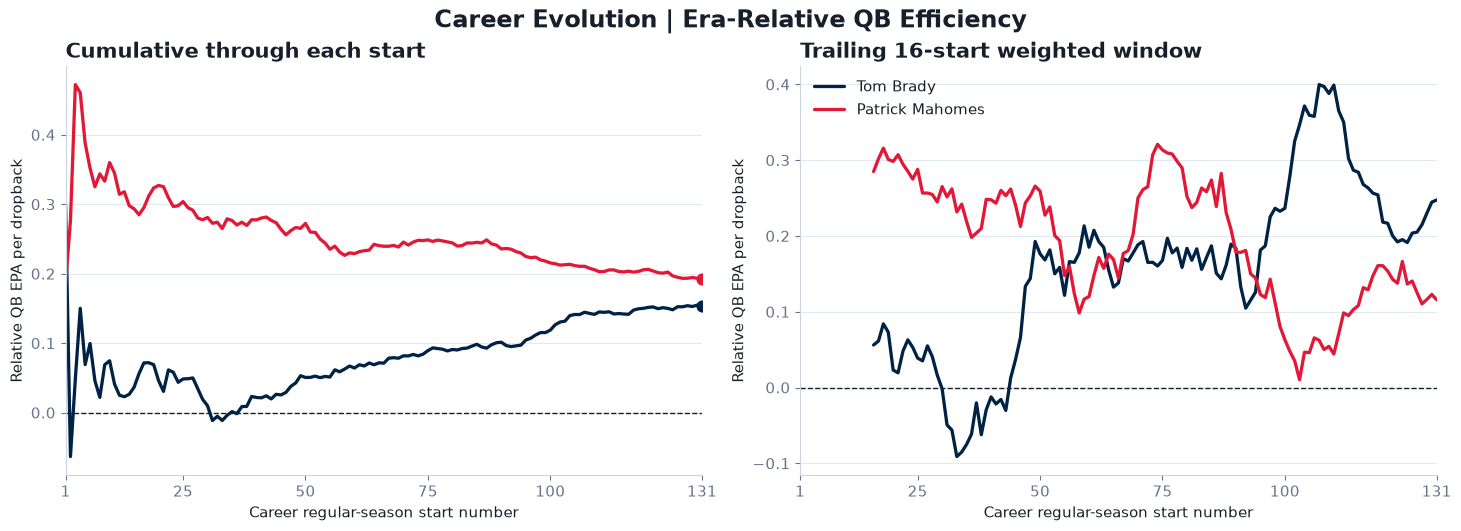

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(14.5, 5.2), sharex=True, layout="constrained")
WINDOW = 16
for player in ORDER:
    segment = games.filter(pl.col("player_name") == player).sort("start_no")
    start = np.asarray(segment["start_no"].to_list(), dtype=int)
    n = np.asarray(segment["usable_dropbacks"].to_list(), dtype=float)
    delta = np.asarray(segment["relative_qb_epa_total"].to_list(), dtype=float)
    cumulative = np.cumsum(delta) / np.cumsum(n)
    rolling = np.full(len(n), np.nan)
    for end in range(WINDOW - 1, len(n)):
        left = end - WINDOW + 1
        rolling[end] = delta[left:end+1].sum() / n[left:end+1].sum()
    for ax, series, name in [
        (axs[0], cumulative, "Cumulative"),
        (axs[1], rolling, "Rolling"),
    ]:
        ax.plot(start, series, color=COLORS[player], linewidth=2.35,
                label=player, solid_capstyle="round")
    axs[0].scatter([131], [cumulative[-1]], color=COLORS[player], s=60, zorder=3)

for ax in axs:
    ax.axhline(0, color=INK, linestyle="--", linewidth=1)
    ax.set_xlim(1, 131)
    ax.set_xticks([1, 25, 50, 75, 100, 131])
    ax.grid(axis="y", color=GRID)
    ax.set_xlabel("Career regular-season start number")
    ax.set_ylabel("Relative QB EPA per dropback")
    ax.spines[["top", "right"]].set_visible(False)
axs[0].set_title("Cumulative through each start", loc="left", weight="bold")
axs[1].set_title(f"Trailing {WINDOW}-start weighted window", loc="left", weight="bold")
axs[1].legend(loc="best", frameon=False)
fig.suptitle("Career Evolution | Era-Relative QB Efficiency", fontsize=17, weight="bold")
fig.savefig(FIGURES / "07_era_relative_career_evolution.png", dpi=220, bbox_inches="tight")
plt.show()

## 7. Figure 5 — Season-normalized EPA (dropback-SD units)

As an **additional descriptive lens**, divide the season-relative EPA/DB by the standard deviation of *individual dropback EPA values* across that NFL season:

$$z^{\mathrm{playSD}}_g=\frac{\mathrm{QB\ EPA/DB}_g-\mu_s}{\sigma_s^{\mathrm{dropback}}}$$

For the first 131 starts, we average game-level $z^{\mathrm{playSD}}$ values **weighted by usable dropbacks**. This accounts for changes in the *spread of play-level outcomes* across seasons.

**Do not interpret this as:** an NFL quarterback percentile, the number of standard deviations by which a QB beats other qualified QBs, or a z-test of statistical significance. Those require a separate **QB-level** reference distribution and qualification rule.

player_name,usable_dropbacks,standardized_relative_epa
str,u32,f64
"""Patrick Mahomes""",5381,0.123018
"""Tom Brady""",4607,0.097416


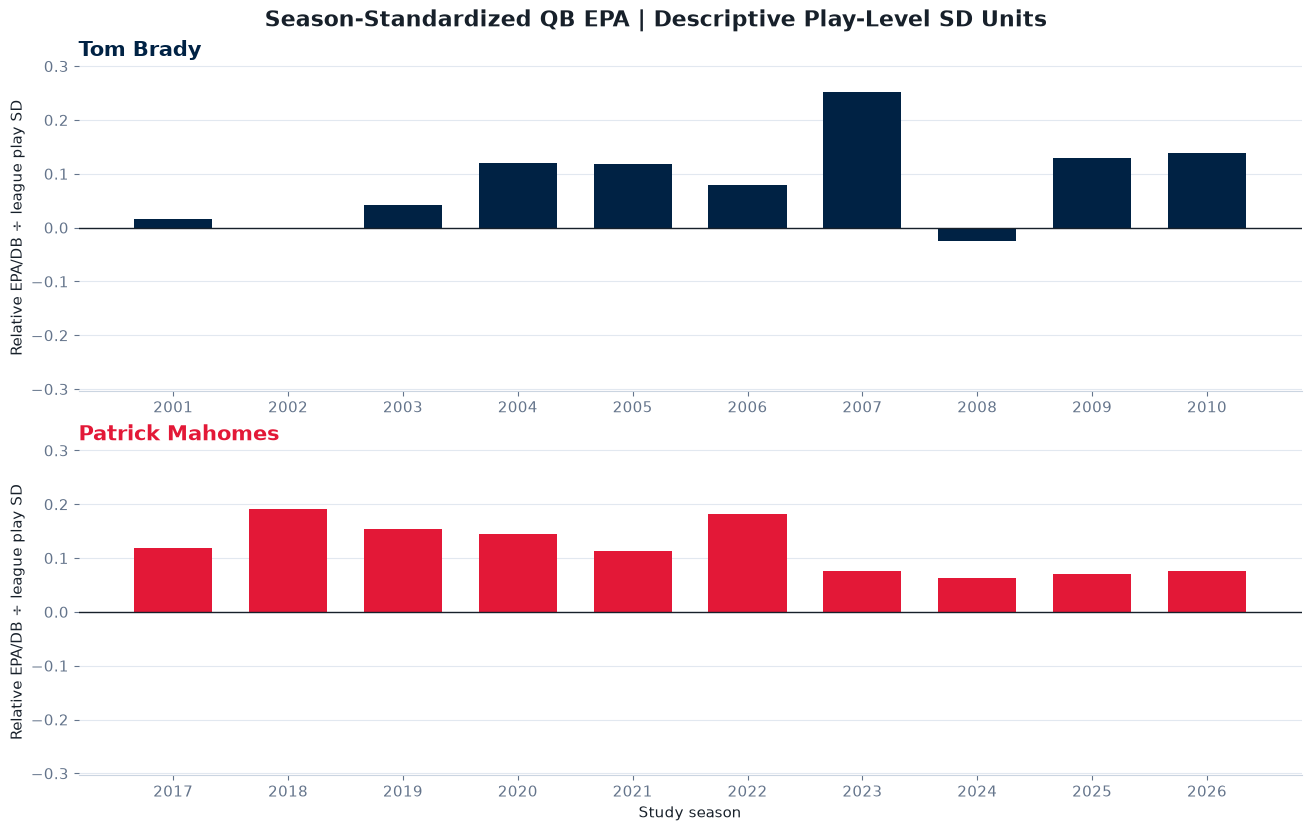

In [8]:
# qb_game_era_adjusted contains the season mean, but not the play-level SD.
normalized_games = games.join(
    league.select("season", "league_qb_epa_std"),
    on="season", how="left", validate="m:1",
)
assert not normalized_games.filter(pl.col("league_qb_epa_std").is_null()).height
normalized_games = normalized_games.with_columns(
    (
        pl.col("relative_qb_epa_per_dropback") / pl.col("league_qb_epa_std")
    ).alias("relative_epa_in_dropback_sd")
)

normalized_seasons = (
    normalized_games.group_by("player_name", "season")
    .agg(
        pl.col("usable_dropbacks").sum().alias("usable_dropbacks"),
        (
            (pl.col("relative_epa_in_dropback_sd") * pl.col("usable_dropbacks")).sum()
            / pl.col("usable_dropbacks").sum()
        ).alias("standardized_relative_epa")
    )
    .sort("player_name", "season")
)
normalized_career = (
    normalized_games.group_by("player_name")
    .agg(
        pl.col("usable_dropbacks").sum().alias("usable_dropbacks"),
        (
            (pl.col("relative_epa_in_dropback_sd") * pl.col("usable_dropbacks")).sum()
            / pl.col("usable_dropbacks").sum()
        ).alias("standardized_relative_epa")
    )
    .sort("player_name")
)

display(normalized_career)

fig, axs = plt.subplots(2, 1, figsize=(13, 8.2), sharey=True, layout="constrained")
normalized_rows = normalized_seasons.to_dicts()
lim = max(0.05, max(abs(float(r["standardized_relative_epa"])) for r in normalized_rows) * 1.20)
for ax, player in zip(axs, ORDER):
    data = sorted((r for r in normalized_rows if r["player_name"] == player),
                  key=lambda r: int(r["season"]))
    xs = np.arange(len(data))
    ys = np.array([float(r["standardized_relative_epa"]) for r in data])
    ax.bar(xs, ys, color=COLORS[player], width=0.68)
    ax.axhline(0, color=INK, linewidth=1)
    ax.set_ylim(-lim, lim)
    ax.set_xticks(xs, [str(r["season"]) for r in data])
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_ylabel("Relative EPA/DB ÷ league play SD")
    ax.set_title(player, color=COLORS[player], weight="bold", loc="left")
    ax.spines[["top", "right", "left"]].set_visible(False)
axs[1].set_xlabel("Study season")
fig.suptitle("Season-Standardized QB EPA | Descriptive Play-Level SD Units",
             fontsize=16, weight="bold")
fig.savefig(FIGURES / "08_season_normalized_qb_epa.png", dpi=220, bbox_inches="tight")
plt.show()

## 8. Relative success rate — a secondary robustness lens

EPA averages can be influenced by a small number of very high- or low-value plays. The **positive-QB-EPA play rate** provides a complementary descriptive perspective. Its era-adjusted version is expressed in **percentage points**, not EPA units.

This rate does **not** replace EPA/DB: it discards information about play magnitude, and a QB can score well on one measure and less well on the other.

In [9]:
summary_rows = {r["player_name"]: r for r in career.to_dicts()}
lines = [
    "| Quarterback | QB EPA/DB | Season-relative EPA/DB | Season-normalized effect | Relative success rate |",
    "|:--|--:|--:|--:|--:|",
]
normalized_lookup = {r["player_name"]: r for r in normalized_career.to_dicts()}
for player in ORDER:
    r = summary_rows[player]
    z = normalized_lookup[player]["standardized_relative_epa"]
    lines.append(
        f"| {player} | {r['qb_epa_per_dropback']:+.4f} | "
        f"{r['relative_qb_epa_per_dropback']:+.4f} | "
        f"{z:+.4f} | {r['relative_qb_epa_success_rate_pp']:+.2f} pp |"
    )
display(Markdown("\n".join(lines)))

| Quarterback | QB EPA/DB | Season-relative EPA/DB | Season-normalized effect | Relative success rate |
|:--|--:|--:|--:|--:|
| Tom Brady | +0.1761 | +0.1542 | +0.0974 | +4.23 pp |
| Patrick Mahomes | +0.2486 | +0.1923 | +0.1230 | +5.86 pp |

## 9. Findings and limitations — complete only after executing the notebook

### Findings to report (fill from observed results)

1. **NFL environment.** Report the historical ranges and any clear departures from a monotonic passing-era narrative (Figure 1).
2. **131-start comparison.** State each QB's *dropback-weighted* absolute and relative EPA/DB, including the observed difference (Figure 2).
3. **Season variation.** Identify robust multi-start seasons separately from unusually high/low one-start season segments (Figure 3).
4. **Career development.** Describe differences between cumulative and trailing 16-start trajectories (Figure 4).
5. **Robustness.** Explain whether play-SD standardized results and relative positive-EPA rates tell a similar story (Figure 5 and Section 8).

### Limitations

- **Not causal.** QB EPA incorporates team context, offensive scheme, opponents, game state, and model assumptions; it does not isolate quarterback talent.
- **League reference is play-weighted.** League baselines include dropbacks by Brady/Mahomes themselves. Comparison to an equally weighted *qualified-QB cohort* requires a separate calculation.
- **Sample segmentation matters.** The study contains exactly the selected 131 starts per QB, not necessarily all games or all starts within each displayed NFL season. Brady 2008 and Mahomes 2017 have only one study start.
- **2026 is partial.** The 2026 NFL baseline is cut off at **2026-10-18** and may change when more games are available. It should not be compared as though it represented a finished season.
- **Scramble restoration.** The source's historical `qb_scramble` tags were used to restore missing dropbacks, particularly in 2001–2005. No untagged QB rushing plays were assumed to be scrambles.
- **Known missing EPA.** One nonstudy-player play (`2019_01_PIT_NE`, play 4166) lacks QB EPA and was omitted from the corresponding NFL baseline; zero was never imputed.
- **No uncertainty intervals yet.** These are descriptive differences for fixed historical samples. We have not modeled game clustering, strength of schedule, or uncertainty and should avoid significance claims.
- **Standardization is not ranking.** Dividing by the league **play-level** standard deviation yields an effect scale, not a QB percentile, QB-rank z-score, or proof of statistical significance.

### Next methodological extensions

- **Three-year relative QB EPA/DB:** define a trailing or centered window with enough neighboring years, document how era boundaries and 2026 are handled, and use a dropback-weighted league baseline.
- **Qualified QB percentile:** compute QB-level season EPA/DB for *all NFL passers*, specify a historically appropriate minimum dropback qualification and evaluate sensitivity to that threshold; use the resulting QB distribution to rank/percentile study players.
- **Sensitivity analysis:** repeat the main comparison with alternative baselines (qualified QB reference, leave-study-QB-out league baseline, and context-adjusted models where justified).

**Research framing:** which QB produced the stronger *observed era-relative performance* across these starts? This notebook helps answer that narrower question, rather than treating EPA as a definitive GOAT ranking.

## 10. Outputs and reproducibility

Figures written automatically to `reports/figures/`:

- `04_nfl_era_baselines.png`
- `05_qb_vs_era_baseline_131.png`
- `06_season_relative_qb_epa.png`
- `07_era_relative_career_evolution.png`
- `08_season_normalized_qb_epa.png`

Existing validated tables under `data/processed/` are never overwritten. To regenerate plots, rerun this notebook from the first cell after rebuilding its upstream processed tables. The narrative findings above deliberately contain no invented values and should be finalized only after inspecting real outputs.

**Data provenance:** `docs/era_adjustment_baseline_decisions.md` and `docs/era_adjusted_qb_methodology.md`.